# Sentiment analysis with an RNN

Predict whether an IMDB movie review is positive or negative.
This is a **many-to-one** task: we read the whole review and classify from the final hidden state.

Pipeline: tokenize → vocabulary → embedding → `nn.RNN` → linear layer → 2 scores.

In [11]:
import random
import re
from collections import Counter
import torch
import torch.nn as nn
import torch.optim as optim
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from torch.utils.data import Dataset, DataLoader
from datasets import load_dataset

SEED = 43
random.seed(SEED)
torch.manual_seed(SEED)

# datasets 
The datasets package is from hugging face and can be installed like this:
```python
import sys
!{sys.executable} -m pip install --upgrade datasets
```


## 1. Load the IMDB data

The Hugging Face version of IMDB already comes split into 25,000 training and 25,000 test reviews. We merge them into one table of 50,000 labelled reviews and make our own 80/20 split.

Labels are already integers: `0` = negative, `1` = positive. No label encoding is needed.

In [12]:
hf_dataset = load_dataset("stanfordnlp/imdb")
print(hf_dataset["train"][0])   # look at one raw example: {'text': ..., 'label': ...}

df = pd.concat(
    [
        pd.DataFrame(hf_dataset["train"]),
        pd.DataFrame(hf_dataset["test"]),
    ],
    ignore_index=True,
)
print(df.shape)                 # expect (50000, 2)

{'text': 'I rented I AM CURIOUS-YELLOW from my video store because of all the controversy that surrounded it when it was first released in 1967. I also heard that at first it was seized by U.S. customs if it ever tried to enter this country, therefore being a fan of films considered "controversial" I really had to see this for myself.<br /><br />The plot is centered around a young Swedish drama student named Lena who wants to learn everything she can about life. In particular she wants to focus her attentions to making some sort of documentary on what the average Swede thought about certain political issues such as the Vietnam War and race issues in the United States. In between asking politicians and ordinary denizens of Stockholm about their opinions on politics, she has sex with her drama teacher, classmates, and married men.<br /><br />What kills me about I AM CURIOUS-YELLOW is that 40 years ago, this was considered pornographic. Really, the sex and nudity scenes are few and far be

## 2. Tokenize

An RNN reads a *sequence of tokens*, so we first turn each review into a list of words. Here we use a very simple tokenization procedure for demonstration purposes.

1. lowercase all text
2. replace the HTML line break `<br />` (it appears in many reviews) with a space
3. keep runs of letters, digits and apostrophes; punctuation is dropped

In [13]:
def tokenize(text):
    text = text.lower().replace("<br />", " ")
    return re.findall(r"[a-z0-9']+", text)

df["text"] = df["text"].apply(tokenize)
print(df["text"][0][:15])       # first 15 tokens of the first review

['i', 'rented', 'i', 'am', 'curious', 'yellow', 'from', 'my', 'video', 'store', 'because', 'of', 'all', 'the', 'controversy']


## 3. Train/test split and vocabulary

We hold out 20% of the reviews for testing. The split comes **first**, and the vocabulary is built from the **training reviews only**. 

Vocabulary conventions:

- index `0` = `<pad>`, used to fill short reviews up to a fixed length
- index `1` = `<unk>`, used for any word not in the vocabulary
- words that occur **fewer than 2 times** in the training data are dropped and map to `<unk>`. Words seen only once are mostly typos and names, and each would otherwise get its own embedding row, which encourages overfitting.

In [14]:
train_data, test_data = train_test_split(df, test_size=0.2, random_state=SEED)
train_data, test_data = train_data.copy(), test_data.copy()

counts = Counter(w for tokens in train_data["text"] for w in tokens)
vocab = ["<pad>", "<unk>"] + [w for w, c in counts.most_common() if c >= 2]
word_to_idx = {w: i for i, w in enumerate(vocab)}

print(f"train: {len(train_data)}, test: {len(test_data)}")
print(f"vocabulary size: {len(vocab)}")

train: 40000, test: 10000
vocabulary size: 64843


## 4. Words to integers, fixed length

Each review is:

1. **truncated** to `max_length` = 250 tokens (last 250 words, more likely to have the sentiment)
2. **mapped** to integer ids
3. **padded** with `0` up to exactly 250 entries

We also store the **true length** (before padding). The model uses it with `pack_padded_sequence` so that the RNN stops at the last real word and never reads the padding.

In [15]:
max_length = 250

def encode_and_pad(tokens):
    encoded = [word_to_idx.get(w, 1) for w in tokens[:max_length]]
    length = len(encoded)
    return encoded + [0] * (max_length - length), length

train_data[["text", "length"]] = train_data["text"].apply(lambda t: pd.Series(encode_and_pad(t)))
test_data[["text", "length"]]  = test_data["text"].apply(lambda t: pd.Series(encode_and_pad(t)))

# Output sanity check

In [17]:
row = train_data.iloc[0]
print("true length:", row["length"])
print("ids:", row["text"][:12], "...")
print("words:", [vocab[i] for i in row["text"][:12]])
print("shortest review in train:", train_data["length"].min())  

true length: 116
ids: [70, 9, 435, 5230, 68, 10, 67, 21, 262, 12, 294, 90] ...
words: ['well', 'it', 'certainly', 'stunned', 'me', 'i', 'can', 'not', 'believe', 'that', 'someone', 'made']
shortest review in train: 6


## Dataset and DataLoader
`SentimentDataset` hands PyTorch one example at a time: the padded word indices, the label (1 = positive, 0 = negative) and the true length. The `DataLoader` groups these into batches of 32 and shuffles the training set each epoch.

In [18]:
class SentimentDataset(Dataset):
    def __init__(self, data):
        self.texts = data['text'].values
        self.labels = data['label'].values
        self.lengths = data['length'].values
    
    def __len__(self):
        return len(self.texts)
    
    def __getitem__(self, idx):
        text = self.texts[idx]
        label = self.labels[idx]
        length = self.lengths[idx] # true, unpadded length
        return (torch.tensor(text, dtype=torch.long), 
                torch.tensor(label, dtype=torch.long), 
                torch.tensor(length, dtype=torch.long))

train_dataset = SentimentDataset(train_data)
test_dataset = SentimentDataset(test_data)

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=32, shuffle=False)

In [19]:
if torch.backends.mps.is_available():
  device = torch.device("mps")
  print("Using Apple Silicon GPU (MPS)")
elif torch.cuda.is_available():
  device = torch.device("cuda")
  print("Using NVIDIA GPU (CUDA)")
else:
  device = torch.device("cpu")
  print("Using CPU")

Using Apple Silicon GPU (MPS)


## The model
Embedding layer → RNN → dropout → linear layer. We use only the **final hidden state** `h_n` (the state after the last real word) to classify the review. The two outputs are raw scores; softmax is applied inside the loss function.

In [20]:
class SentimentRNN(nn.Module):
    def __init__(self, vocab_size, embed_size, hidden_size, output_size):
        super().__init__()
        self.hidden_size = hidden_size
        self.embedding = nn.Embedding(vocab_size, embed_size, padding_idx=0)
        self.rnn = nn.RNN(embed_size, hidden_size, batch_first=True)
        self.fc = nn.Linear(hidden_size, output_size)
        self.dropout = nn.Dropout(0.35)
    
    def forward(self, x, lengths):
        x = self.embedding(x)
        ## pack__padded_sequences tells pytorch the true length of each sequanece, so the RNN skips the padding
        ## h_n is then the hidden state right after the last word
        packed = nn.utils.rnn.pack_padded_sequence(x, lengths.cpu(), batch_first=True, enforce_sorted=False)
        _, h_n = self.rnn(packed)
        out = self.fc(self.dropout(h_n[-1]))
        return out

vocab_size = len(vocab) + 1
embed_size = 128
hidden_size = 128
output_size = 2 
model = SentimentRNN(vocab_size, embed_size, hidden_size, output_size).to(device)

## Training
Cross-entropy loss with the Adam optimizer. Gradient clipping rescales the gradient whenever its norm exceeds 5.0, which guards against exploding gradients.

In [21]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=0.001)

num_epochs = 10
losses = []
for epoch in range(num_epochs):
    model.train()
    epoch_loss = 0
    for texts, labels, lengths in train_loader:
        texts = texts.to(device)
        labels = labels.to(device)
        outputs = model(texts, lengths)
        loss = criterion(outputs, labels)
        
        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=5.0)
        optimizer.step()
        
        epoch_loss += loss.item()
    losses.append(epoch_loss / len(train_loader))
    print(f'Epoch [{epoch+1}/{num_epochs}], Loss: {epoch_loss / len(train_loader):.4f}')

Epoch [1/10], Loss: 0.6640
Epoch [2/10], Loss: 0.5726
Epoch [3/10], Loss: 0.5165
Epoch [4/10], Loss: 0.4613
Epoch [5/10], Loss: 0.4034
Epoch [6/10], Loss: 0.3562
Epoch [7/10], Loss: 0.3213
Epoch [8/10], Loss: 0.2879
Epoch [9/10], Loss: 0.2729
Epoch [10/10], Loss: 0.2381


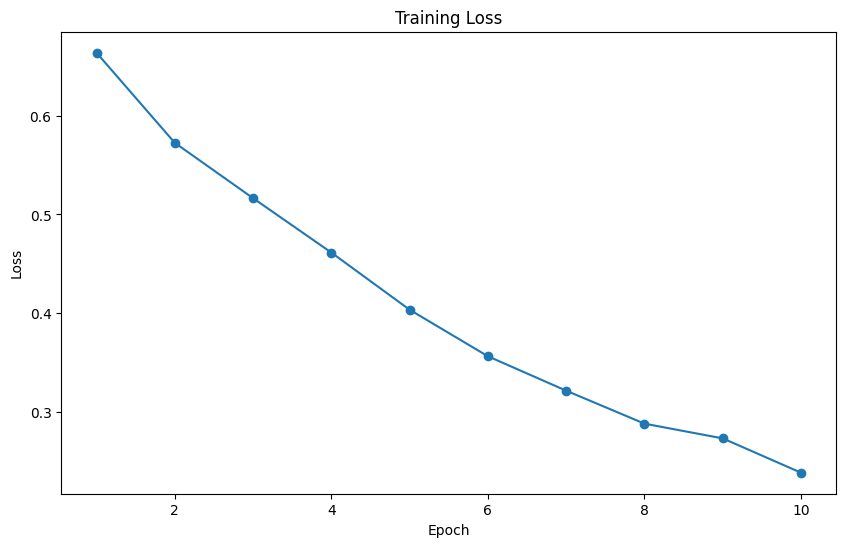

In [22]:
plt.figure(figsize=(10, 6))
plt.plot(range(1, num_epochs + 1), losses, marker='o')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training Loss')
plt.show()

## Evaluation
Accuracy on the held-out test set. `model.eval()` turns dropout off, and `torch.no_grad()` skips gradient bookkeeping because we are not updating weights.

In [23]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for texts, labels, lengths in test_loader:
        texts = texts.to(device)
        labels = labels.to(device)
        outputs = model(texts, lengths)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy: {accuracy:.2f}%')

Accuracy: 78.40%


## Baseline
The test set is almost balanced (49.45% positive), so always guessing "negative" would score about 50.5%. That is the chance level to compare against.

In [ ]:
tlabs = test_dataset.labels
n_test = len(tlabs)
n_pos = sum([1 for l in tlabs if l == 1])
prop = 100.0* n_pos / n_test
print(f"{n_pos}/{n_test}={prop}%")

4918/10000=49.18%


## Training accuracy
Accuracy on the training data, to compare with test accuracy. The large gap between the two (97.85% vs 73.94%) is a sign of overfitting.

In [25]:
model.eval()
correct = 0
total = 0
with torch.no_grad():
    for texts, labels, lengths in train_loader:
        texts = texts.to(device)
        labels = labels.to(device)
        outputs = model(texts, lengths)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total
print(f'Accuracy: {accuracy:.2f}%')

Accuracy: 93.33%
